# Соревнование Kaggle (тестовое задание ecom.tech)
Задание: спрогнозировать для каждого даркстора будущий дефицит курьеров - количество курьеров, которое нужно нанять, чтобы в будущем доставлять все заказы без опозданий.

Значение дифицита, равное нулю, означает, что даркстор укомплектован и с учетом прогнозного числа заказов и динамики курьерских смен, дополнительный найм не требуется.
* Ссылка: `kaggle.com/competitions/intern-task-regression-courier-deficit-challenge`

facts -  реальное кол-во курьеров, которое нужно было, чтобы обслужить все заказы за предыдущую неделю. Также содержит фактическую нагрузку за прошедшую неделю, число курьеров, предлагавших свои услуги (не обязательно вышедших на смены), фактическое кол-во заказов, лайфтайм даркстора, название города, общее число трудоустроенных курьеров, число курьеров, вышедших на смены, расходы на маркетинг, факт повышенного спроса.

shifts - прогноз числа заказов на неделю и запланированная нагрузка (число заказов на одного курьера в час), а также прогнозное число курьеров, чтобы обслужить эти заказы. Каждая дата - понедельник соответствующей недели, на которую приведены прогнозные значения.

train - содержит для каждого даркстора на даты в прошлом дефицит курьеров в поле target.

test.csv - тестовый датасет, упорядочен по store_id. Необходимо сделать прогноз для каждого из приведенных дарксторов НА НЕДЕЛЮ (на 24 ноября 2025г).

### FACTS
- `calendar_dt` - дата в формате YYYY-MM-DD
- `store_id` - идентификатор даркстора
- `fact_staff_value_lag_1` - фактическое число человек, необходимое, чтобы обслужить все заказы на прошлой неделе,
- `fact_load_factor_lag_1` - фактическая нагрузка на курьеров на прошлой неделе,
- `num_available_couriers_lag_1` - число курьеров, предложивших свои услуги за предыдущую неделю,
- `fact_num_orders_lag_1` - фактическое число заказов за предыдущую неделю,
- `fact_percent_lateness_lag_1` - процент опозданий за предыдущую неделю,
- `store_lifetime_in_days` - число дней функционирования даркстора,
- `city_nm` - город функционирования даркстора,
- `fact_staff_churn` - число курьеров, уволившихся из компании,
- `flag_high_load_lag_1` - признак повышенного спроса за предыдущую неделю,
- `marketing_costs_lag_1` - затраты на маркетинг, осуществленные за предыдущую неделю,
- `fact_couriers_with_shifts_lag_1` - число курьеров, выходивших на смены на предыдущей неделе.

### SHIFTS
- `calendar_dt` - дата в формате YYYY-MM-DD
- `store_id` - идентификатор даркстора
- `predicted_staff_value` - предсказанное число человек, необходимое, чтобы обслужить все заказы на неделе прогноза,
- `predicted_num_orders` - предсказанное число заказов на неделю прогноза,
- `predicted_load_factor` - предсказанная нагрузка на курьеров (число заказов в час, которое приходится на одного курьера) на неделю прогноза.

In [26]:
# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import lightgbm as lgb
from catboost import CatBoostRegressor
import xgboost as xgb

from sklearn.model_selection import KFold

In [28]:
df_facts = pd.read_csv('facts.csv')
df_sample = pd.read_csv('sample_submission.csv')
df_shifts = pd.read_csv('shifts_prediction.csv')
df_test = pd.read_csv('test.csv')
df_train = pd.read_csv('train.csv')

In [29]:
df_facts.head()

,calendar_dt,store_id,fact_staff_value_lag_1,fact_load_factor_lag_1,num_available_couriers_lag_1,fact_num_orders_lag_1,fact_percent_lateness_lag_1,city_nm,store_lifetime_in_days,fact_staff_churn,flag_high_load_lag_1,marketing_costs_lag_1,fact_couriers_with_shifts_lag_1
0,2025-11-03,000fade4-e8dc-11ed-b10a-08c0eb31fffb,1,0.526316,10,10,NaN,Ульяновск,888.0,1.0,1,3.683577e+08,19.0
1,2025-11-10,000fade4-e8dc-11ed-b10a-08c0eb31fffb,8,1.941176,13,33,69.565217,Ульяновск,895.0,1.0,1,NaN,17.0
2,2025-11-17,000fade4-e8dc-11ed-b10a-08c0eb31fffb,8,2.400000,12,36,66.666667,Ульяновск,902.0,4.0,1,4.254502e+10,15.0
3,2025-11-24,000fade4-e8dc-11ed-b10a-08c0eb31fffb,11,2.294118,12,39,94.444444,Ульяновск,909.0,2.0,1,NaN,17.0
4,2025-11-03,0022f1b0-b8f8-11ee-b10b-08c0eb31fffb,1,0.833333,10,10,NaN,Набережные Челны,617.0,1.0,1,NaN,12.0


У файлов train, shifts и facts есть общие колонки: дата и id магазина, поэтому можно объединить датасеты, используя эти колонки как ключи. Но для начала отформатируем даты и отсортируем их 

In [30]:
df_facts['calendar_dt'] = pd.to_datetime(df_facts['calendar_dt'])
df_shifts['calendar_dt'] = pd.to_datetime(df_shifts['calendar_dt'])
df_train['calendar_dt'] = pd.to_datetime(df_train['calendar_dt'])

df_test['calendar_dt'] = pd.to_datetime('2025-11-24')
df_test['target'] = np.nan

df = pd.concat([df_train, df_test], ignore_index=True)
df = df.merge(df_facts, on=['calendar_dt','store_id'], how='left')
df = df.merge(df_shifts, on=['calendar_dt','store_id'], how='left')

df = df.sort_values(by=['store_id','calendar_dt',]).reset_index(drop=True)

In [31]:
df['calendar_dt'].value_counts()

calendar_dt
2025-11-17    2439
2025-11-24    2438
2025-11-10    2436
2025-11-03    2431
2025-10-27      13
              ... 
2024-01-15       4
2024-01-08       4
2024-01-01       4
2024-02-12       4
2024-02-19       1
Name: count, Length: 99, dtype: int64

Можно заметить, что на последних трех неделях сосредоточено 89% всей выборки. 

Если применить TimeSeriesSplit, то модель потеряет почти треть данных для обучения. Поэтому придется применять kfold. В 4 из 5 фолдах каждая модель видит куски последней недели, а итоговый прогноз формируется из усреднения предсказаний по фолдам. Это смягчает эффект возможного переобчения под конкретные дни. 

## Baseline

Будем обучать LightGBM, XGBoost и CatBoost

In [32]:
def wape(y_true, y_pred):
    return np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true))

kf = KFold(n_splits=5, shuffle=True, random_state=42)

base = df[df['calendar_dt'] < '2025-11-24'].reset_index(drop=True)
y_base = base['target'].values
test_raw = df[df['calendar_dt'] == '2025-11-24'].reset_index(drop=True)

def rule_global(tr, val):
    return np.full(len(val), np.median(y_base[tr]))

def rule_store(tr, val):
    med = base.iloc[tr].groupby('store_id')['target'].median()
    return base.iloc[val]['store_id'].map(med).fillna(np.median(y_base[tr])).values

def deficit(tr, val):
    v = base.iloc[val]
    pred = (v['predicted_staff_value'] - v['fact_couriers_with_shifts_lag_1']).clip(lower=0)
    return pred.fillna(np.median(y_base[tr])).values

rules = {
    'глобальная медиана': rule_global,
    'медиана по магазину': rule_store,
    'дефицит курьеров': deficit,
}

rule_scores = {}
for name, rule in rules.items():
    scores = [wape(y_base[val], np.round(rule(tr, val))) for tr, val in kf.split(base)]
    rule_scores[name] = scores
    print(f'{name} WAPE: {np.mean(scores):.4f}  по фолдам: {np.round(scores, 4)}')

глобальная медиана WAPE: 0.8247  по фолдам: [0.8296 0.8092 0.8232 0.8204 0.8412]
медиана по магазину WAPE: 0.6425  по фолдам: [0.6317 0.6567 0.6457 0.6234 0.6553]
дефицит курьеров WAPE: 0.9733  по фолдам: [0.9764 0.978  0.9678 0.9704 0.9736]


count    8220.000000
mean        2.378589
std         2.738420
min         0.000000
25%         0.000000
50%         2.000000
75%         4.000000
max        31.000000
Name: target, dtype: float64
Доля нулей: 33.0%


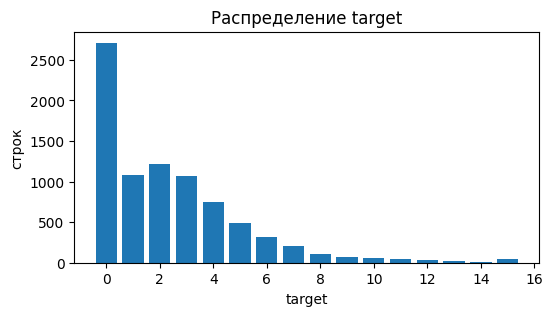

In [33]:
train_eda = df[df['calendar_dt'] < '2025-11-24']
t = train_eda['target']

print(t.describe())
print(f'Доля нулей: {(t == 0).mean():.1%}')

vc_t = t.clip(upper=15).value_counts().sort_index()
plt.figure(figsize=(6, 3))
plt.bar(vc_t.index, vc_t.values)
plt.xlabel('target'); plt.ylabel('строк')
plt.title('Распределение target')
plt.show()

Целевую метрику возьмем MAE, потому что WAPE = MAE*n / сумма реального дефицита

### LGBM_baseline

In [34]:
raw_features = [c for c in base.columns if c not in ['calendar_dt', 'store_id', 'target']]
X_raw = base[raw_features].copy()
X_raw['city_nm'] = X_raw['city_nm'].astype('category')

lgb_scores = []
for fold, (tr, val) in enumerate(kf.split(X_raw)):
    m = lgb.LGBMRegressor(objective='mae', random_state=42, n_jobs=-1, verbose=-1)
    m.fit(X_raw.iloc[tr], y_base[tr])
    
    pred = np.round(np.clip(m.predict(X_raw.iloc[val]), 0, None))
    lgb_scores.append(wape(y_base[val], pred))
    print(f'Fold {fold+1} WAPE: {lgb_scores[-1]:.4f}')

print(f'WAPE: {np.mean(lgb_scores):.4f}')

Fold 1 WAPE: 0.1754
Fold 2 WAPE: 0.1706
Fold 3 WAPE: 0.1730
Fold 4 WAPE: 0.1904
Fold 5 WAPE: 0.1930
WAPE: 0.1805


### CatBoost_baseline

In [35]:
X_cb = base[raw_features].copy()
X_cb['city_nm'] = X_cb['city_nm'].astype(str)
X_cb_test = test_raw[raw_features].copy()
X_cb_test['city_nm'] = X_cb_test['city_nm'].astype(str)

cb_scores, cb_test_preds = [], []
for fold, (tr, val) in enumerate(kf.split(X_cb)):
    m = CatBoostRegressor(loss_function='MAE', cat_features=['city_nm'],
                          random_seed=42, thread_count=-1, verbose=0)
    m.fit(X_cb.iloc[tr], y_base[tr])

    pred = np.round(np.clip(m.predict(X_cb.iloc[val]), 0, None))
    cb_scores.append(wape(y_base[val], pred))
    cb_test_preds.append(m.predict(X_cb_test))
    print(f'Fold {fold+1} WAPE: {cb_scores[-1]:.4f}')

print(f'WAPE: {np.mean(cb_scores):.4f}')   

Fold 1 WAPE: 0.1609
Fold 2 WAPE: 0.1641
Fold 3 WAPE: 0.1584
Fold 4 WAPE: 0.1763
Fold 5 WAPE: 0.1842
WAPE: 0.1688


### XGBoost_baseline

In [36]:
X_xgb = base[raw_features].copy()
X_xgb['city_nm'] = X_xgb['city_nm'].astype('category')

xgb_scores = []
for fold, (tr, val) in enumerate(kf.split(X_xgb)):
    m = xgb.XGBRegressor(objective='reg:absoluteerror', enable_categorical=True,
                         tree_method='hist', random_state=42, n_jobs=-1)
    m.fit(X_xgb.iloc[tr], y_base[tr])

    pred = np.round(np.clip(m.predict(X_xgb.iloc[val]), 0, None))
    xgb_scores.append(wape(y_base[val], pred))
    print(f'Fold {fold+1} WAPE: {xgb_scores[-1]:.4f}')

print(f'WAPE: {np.mean(xgb_scores):.4f}')

Fold 1 WAPE: 0.1782
Fold 2 WAPE: 0.1714
Fold 3 WAPE: 0.1635
Fold 4 WAPE: 0.1881
Fold 5 WAPE: 0.1977
WAPE: 0.1798


## EDA

In [37]:
pd.notna(df).sum()

calendar_dt                        10658
store_id                           10658
target                              8220
fact_staff_value_lag_1             10658
fact_load_factor_lag_1             10543
num_available_couriers_lag_1       10658
fact_num_orders_lag_1              10658
fact_percent_lateness_lag_1         8201
city_nm                            10658
store_lifetime_in_days             10658
fact_staff_churn                   10658
flag_high_load_lag_1               10658
marketing_costs_lag_1               7455
fact_couriers_with_shifts_lag_1    10543
predicted_staff_value              10657
predicted_num_orders               10657
predicted_load_factor              10657
dtype: int64

Пропусков в колонках не так много, поэтому заменим их на локальную медиану (медиану по магазину, а не по всей выборке)

После предыдущей обработки остались пропущенные значения, это значения, где у магазинов вообще не было информации по этим критериям, поэтому их заменим их на медиану по всем магазинам

В fact_percent_lateness_lag_1 пропусков много, поэтому пока оставим без изменений

In [38]:
historical_data = df[df['calendar_dt'] < '2025-11-24']

cols_to_fill = [
    'fact_couriers_with_shifts_lag_1', 'fact_load_factor_lag_1', 
    'predicted_num_orders', 'predicted_load_factor', 'predicted_staff_value'
]

for i in cols_to_fill:
    store_medians = historical_data.groupby('store_id')[i].median()
    df[i] = df[i].fillna(df['store_id'].map(store_medians))
    df[i] = df[i].fillna(historical_data[i].median())

Создадим новые признаки, которые помогут Catboost лучше обучиться на данных:
- Извлечем номера месяцов и недель, 
- Создадим новый признак: если в проценте опозданий за пред. неделю стоит NaN, то значение будет 1, иначе - 0. 
- А в исходной колонке заменим значения NaN на -1. 
- Создадим разницы между предсказанными значениями и фактическими (и их процентные соотношения). В теории, это должно помочь найти зависимости
- Создадим лаги на 2 недели, чтобы модель увидела тенденции
- Добавим скользящее среднее
- Заменим пропуски на невозможное число, чтобы модель точно заметила их

In [39]:
df['month'] = df['calendar_dt'].dt.month
df['week'] = df['calendar_dt'].dt.isocalendar().week.astype(int)

df['lateness_missing'] = df['fact_percent_lateness_lag_1'].isna().astype(int)

df['fact_percent_lateness_rolling'] = df.groupby('store_id')['fact_percent_lateness_lag_1'].transform(lambda x: x.rolling(window=3, min_periods=1).mean())

df['fact_percent_lateness_lag_1'] = df['fact_percent_lateness_lag_1'].fillna(-1)

df['delta_staff_value'] = df['predicted_staff_value'] - df['fact_staff_value_lag_1']
df['delta_num_oreders'] = df['predicted_num_orders'] - df['fact_num_orders_lag_1']
df['delta_load_factor'] = df['predicted_load_factor'] - df['fact_load_factor_lag_1']

df['delta_staff_value_percent'] = (df['predicted_staff_value'] - df['fact_staff_value_lag_1']) / df['fact_staff_value_lag_1']
df['delta_num_orders_percent'] = (df['predicted_num_orders'] - df['fact_num_orders_lag_1']) / df['fact_num_orders_lag_1']
df['delta_load_factor_percent'] = (df['predicted_load_factor'] - df['fact_load_factor_lag_1']) / df['fact_load_factor_lag_1']
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# df['target_lag1'] = df.groupby('store_id')['target'].shift(1)
# df['target_lag2'] = df.groupby('store_id')['target'].shift(2)

df['fact_num_orders_lag_2'] = df.groupby('store_id')['fact_num_orders_lag_1'].shift(1)
df['fact_staff_value_lag_2'] = df.groupby('store_id')['fact_staff_value_lag_1'].shift(1)
df['fact_load_factor_lag_2'] = df.groupby('store_id')['fact_load_factor_lag_1'].shift(1)
df['fact_percent_lateness_lag_2'] = df.groupby('store_id')['fact_percent_lateness_lag_1'].shift(1)

# df['target_rolling'] = df.groupby('store_id')['target_lag1'].transform(lambda x: x.rolling(window=3, min_periods=1).mean())
df['fact_num_orders_rolling'] = df.groupby('store_id')['fact_num_orders_lag_1'].transform(lambda x: x.rolling(window=3, min_periods=1).mean())
df['fact_staff_value_rolling'] = df.groupby('store_id')['fact_staff_value_lag_1'].transform(lambda x: x.rolling(window=3, min_periods=1).mean())
df['fact_load_factor_rolling'] = df.groupby('store_id')['fact_load_factor_lag_1'].transform(lambda x: x.rolling(window=3, min_periods=1).mean())

cols = ['fact_num_orders_lag_2','fact_staff_value_lag_2','fact_load_factor_lag_2','fact_percent_lateness_lag_2',
        'fact_num_orders_rolling','fact_staff_value_rolling','fact_load_factor_rolling','fact_percent_lateness_rolling']
for i in cols:
    df[i] = df[i].fillna(-1)

3 признака были закомментированы, потому что они улучшали результат, но в kaggle результат становился хуже 

## Модели на признаках

Создадим тестовую и тренировочную выборки, категариальные и числовые признаки.

In [40]:
df['city_nm'] = df['city_nm'].astype('category')

train_data = df[df['calendar_dt'] < '2025-11-24'].copy()
test = df[df['calendar_dt'] == '2025-11-24'].copy()

num_features = [i for i in df.columns if i not in ['calendar_dt', 'store_id', 'target']]
cat_features = ['city_nm']

x = train_data[num_features]
y = train_data['target']
xtest = test[num_features]

print(f'Train shape: {x.shape}')
print(f'Test shape: {xtest.shape}')

Train shape: (8220, 31)
Test shape: (2438, 31)


Посмотрим карту корреляций. Высокой корреляции признаков можно не бояться, потому что деревья устойчивы к мультиколлинеарности, а бустинг способен улавливать нелинейные связи

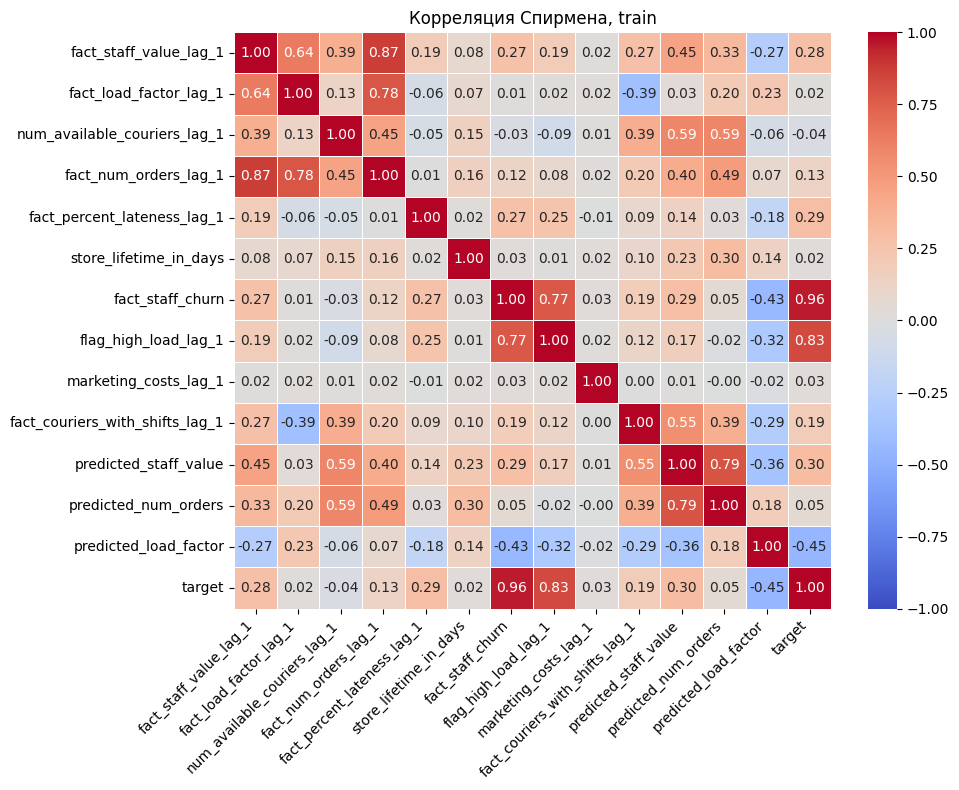

In [41]:
cols = [
    'fact_staff_value_lag_1', 'fact_load_factor_lag_1', 'num_available_couriers_lag_1',
    'fact_num_orders_lag_1', 'fact_percent_lateness_lag_1', 'store_lifetime_in_days',
    'fact_staff_churn', 'flag_high_load_lag_1', 'marketing_costs_lag_1',
    'fact_couriers_with_shifts_lag_1', 'predicted_staff_value',
    'predicted_num_orders', 'predicted_load_factor', 'target'
]

cm = (train_data[cols].replace({'fact_percent_lateness_lag_1': -1}, np.nan).corr('spearman'))

plt.figure(figsize=(10, 8))
sns.heatmap(cm,annot=True,fmt='.2f',cmap='coolwarm',vmin=-1,vmax=1,linewidths=.5)

plt.xticks(rotation=45, ha='right')
plt.title('Корреляция Спирмена, train')
plt.tight_layout()
plt.show()


Введем OOF (out-of-fold) предсказания. Это предсказания на обучающей выборке, в которых каждая строка предсказана моделью, не видевшей эту строку при обучении. За 5 фолдов каждая строка train получает ровно одно такое предсказание, поэтому по ним можно считать общую метрику и сравнивать модели и бленды.

### LGBM

In [42]:
def wape(y_true, y_pred):
    return np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true))

kf = KFold(n_splits=5, shuffle=True, random_state=42)

predictions = np.zeros(len(xtest))
wape_list = []

oof_lgb = np.zeros(len(x)) 

for fold, (train_id, val_id) in enumerate(kf.split(x)):
    xtrain, ytrain = x.iloc[train_id], y.iloc[train_id]
    xval, yval = x.iloc[val_id], y.iloc[val_id]
    
    model = lgb.LGBMRegressor(
        n_estimators=1500,
        learning_rate=0.03,
        num_leaves=22,
        max_depth=5,
        objective='MAE',
        metric='MAE',
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )
    
    model.fit(
        X=xtrain,
        y=ytrain,
        eval_set=[(xval, yval)],
        eval_metric='MAE',
        categorical_feature=cat_features,
        callbacks=[lgb.early_stopping(stopping_rounds=100, verbose=False)]
    )
    
    val_pred = model.predict(xval)
    val_pred = np.clip(val_pred, 0, None)
    
    oof_lgb[val_id] = val_pred

    wape_fold = wape(yval.values, np.round(val_pred))
    print(f"Fold {fold+1} WAPE: {wape_fold:.4f}")
    wape_list.append(wape_fold)
    
    predictions += model.predict(xtest) / kf.n_splits

print(f"Средняя WAPE: {np.mean(wape_list):.4f}")

Fold 1 WAPE: 0.1646
Fold 2 WAPE: 0.1613
Fold 3 WAPE: 0.1608
Fold 4 WAPE: 0.1771
Fold 5 WAPE: 0.1832
Средняя WAPE: 0.1694


### CatBoost

In [43]:
x_cb = x.copy()
xtest_cb = xtest.copy()
x_cb['city_nm'] = x_cb['city_nm'].astype(str)
xtest_cb['city_nm'] = xtest_cb['city_nm'].astype(str)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

predictions_cb = np.zeros(len(xtest_cb))
oof_cb = np.zeros(len(x_cb))
wape_list_cb = []

for fold, (train_id, val_id) in enumerate(kf.split(x_cb)):
    xtrain, ytrain = x_cb.iloc[train_id], y.iloc[train_id]
    xval, yval = x_cb.iloc[val_id], y.iloc[val_id]

    model = CatBoostRegressor(
        iterations=3000,
        learning_rate=0.03,
        depth=6,
        rsm=0.8,
        loss_function='MAE',
        eval_metric='MAE',
        cat_features=cat_features,
        early_stopping_rounds=100,
        random_seed=42,
        thread_count=-1,
        verbose=0
    )

    model.fit(xtrain, ytrain, eval_set=(xval, yval))

    val_pred = model.predict(xval)
    val_pred = np.clip(val_pred, 0, None)
    oof_cb[val_id] = val_pred
    
    wape_fold = wape(yval.values, np.round(val_pred))
    print(f"Fold {fold+1} WAPE: {wape_fold:.4f}")
    wape_list_cb.append(wape_fold)

    predictions_cb += model.predict(xtest_cb) / kf.n_splits

print(f"WAPE: {np.mean(wape_list_cb):.4f}")

Fold 1 WAPE: 0.1646
Fold 2 WAPE: 0.1678
Fold 3 WAPE: 0.1632
Fold 4 WAPE: 0.1799
Fold 5 WAPE: 0.1802
WAPE: 0.1712


### XGBoost

In [44]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

predictions_xgb = np.zeros(len(xtest))
oof_xgb = np.zeros(len(x))
wape_list_xgb = []

for fold, (train_id, val_id) in enumerate(kf.split(x)):
    xtrain, ytrain = x.iloc[train_id], y.iloc[train_id]
    xval, yval = x.iloc[val_id], y.iloc[val_id]

    model = xgb.XGBRegressor(
        n_estimators=3000,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=7,       
        subsample=0.8,
        colsample_bytree=0.7,
        reg_lambda=5,
        objective='reg:absoluteerror',
        eval_metric='mae',
        enable_categorical=True,
        tree_method='hist',
        early_stopping_rounds=100,
        random_state=42,
        n_jobs=-1
    )

    model.fit(xtrain, ytrain, eval_set=[(xval, yval)], verbose=False)

    val_pred = model.predict(xval)
    val_pred = np.clip(val_pred, 0, None)
    oof_xgb[val_id] = val_pred

    wape_fold = wape(yval.values, np.round(val_pred))
    print(f"Fold {fold+1} WAPE: {wape_fold:.4f}")
    wape_list_xgb.append(wape_fold)

    predictions_xgb += model.predict(xtest) / kf.n_splits

print(f"WAPE: {np.mean(wape_list_xgb):.4f}")

Fold 1 WAPE: 0.1636
Fold 2 WAPE: 0.1696
Fold 3 WAPE: 0.1654
Fold 4 WAPE: 0.1756
Fold 5 WAPE: 0.1844
WAPE: 0.1717


### LGBM+XGB

In [45]:
def oof_wape(pred):
    return [wape(y.values[val], np.round(np.clip(pred[val], 0, None))) for _, val in kf.split(x)]

blend_xgb = (oof_lgb + oof_xgb) / 2

res_xgb = pd.DataFrame({
    'LightGBM': oof_wape(oof_lgb),
    'XGBoost': oof_wape(oof_xgb),
    'LGBM+XGB': oof_wape(blend_xgb),
}, index=[f'fold {i+1}' for i in range(5)])
res_xgb.loc['mean'] = res_xgb.mean()
print(res_xgb.round(4))

        LightGBM  XGBoost  LGBM+XGB
fold 1    0.1646   0.1636    0.1661
fold 2    0.1613   0.1696    0.1638
fold 3    0.1608   0.1654    0.1597
fold 4    0.1771   0.1756    0.1748
fold 5    0.1832   0.1844    0.1842
mean      0.1694   0.1717    0.1697


### LGBM+CB

In [46]:
def oof_wape(pred):
    return [wape(y.values[val], np.round(np.clip(pred[val], 0, None))) for _, val in kf.split(x)]

blend_cb = (oof_lgb + oof_cb) / 2

res_cb = pd.DataFrame({
    'LightGBM': oof_wape(oof_lgb),
    'CatBoost': oof_wape(oof_cb),
    'LGBM+CB': oof_wape(blend_cb),
}, index=[f'fold {i+1}' for i in range(5)])
res_cb.loc['mean'] = res_cb.mean()
print(res_cb.round(4))

        LightGBM  CatBoost  LGBM+CB
fold 1    0.1646    0.1646   0.1619
fold 2    0.1613    0.1678   0.1600
fold 3    0.1608    0.1632   0.1589
fold 4    0.1771    0.1799   0.1761
fold 5    0.1832    0.1802   0.1817
mean      0.1694    0.1712   0.1677


In [47]:
results = pd.DataFrame({
    'LightGBM': oof_wape(oof_lgb),
    'XGBoost': oof_wape(oof_xgb),
    'CatBoost': oof_wape(oof_cb),
    'LGBM+XGB': oof_wape(blend_xgb),
    'LGBM+CB': oof_wape(blend_cb),
}, index=[f'fold {i+1}' for i in range(5)])
results.loc['mean'] = results.mean()
print(results.round(4))

        LightGBM  XGBoost  CatBoost  LGBM+XGB  LGBM+CB
fold 1    0.1646   0.1636    0.1646    0.1661   0.1619
fold 2    0.1613   0.1696    0.1678    0.1638   0.1600
fold 3    0.1608   0.1654    0.1632    0.1597   0.1589
fold 4    0.1771   0.1756    0.1799    0.1748   0.1761
fold 5    0.1832   0.1844    0.1802    0.1842   0.1817
mean      0.1694   0.1717    0.1712    0.1697   0.1677


Загружаем предсказание в файл

In [48]:
# test_pred = np.clip(predictions, 0, None)

# answer = pd.DataFrame({
#     'store_id':test['store_id'],
#     'target':np.round(test_pred).astype(int) 
# })

# answer.to_csv('answer_gbm.csv', index=False)
# print('Файл готов')

In [49]:
lgb_test_pred = np.clip(predictions, 0, None)
cb_test_pred = np.clip(predictions_cb, 0, None)

blend_test_pred = (lgb_test_pred + cb_test_pred) / 2

answer_blend = pd.DataFrame({
    'store_id': test['store_id'],
    'target': np.round(blend_test_pred).astype(int)
})

answer_blend.to_csv('answer_blend_lgb_cb.csv', index=False)
print('Файл готов')

Файл готов


### Результат в соревновании:
* 0.1779 по метрике WAPE
* Место в лидерборде: 1